# Lecture 2: The RBC Model in Continuous Time

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/johanneswieland/RBC/blob/main/lectures/02_rbc_continuous_time.ipynb)

**Economics 210A: Macroeconomics** · Johannes Wieland

We now build the simplest model that could generate the facts of Lecture 1: a frictionless economy with a representative household and a representative firm, competitive markets, and shocks to productivity and government spending. The model, in the spirit of [Kydland and Prescott (1982)](https://www.jstor.org/stable/1913386), is obviously unrealistic, but it is the benchmark that every later model modifies.

We work in **continuous time**. It is the natural setting for the phase diagram we use to understand the model's dynamics, and it avoids the timing ambiguities that arise when a discrete-time model is analyzed graphically. Every step is checked in code: the steady state, the linearization, the saddle path, and the responses to shocks. At the end we verify the linearized solution against the exact nonlinear transition.

## Readings

- King, R. G., C. I. Plosser, and S. T. Rebelo (1988), "[Production, Growth and Business Cycles: I. The Basic Neoclassical Model](https://doi.org/10.1016/0304-3932%2888%2990030-X)," *Journal of Monetary Economics* 21(2–3).
- King, R. G. and S. T. Rebelo (1999), "[Resuscitating Real Business Cycles](https://doi.org/10.3386/w7534)," *Handbook of Macroeconomics*, Vol. 1B, Ch. 14.
- Barro, R. J. and R. G. King (1984), "[Time-Separable Preferences and Intertemporal-Substitution Models of Business Cycles](https://doi.org/10.2307/1883127)," *Quarterly Journal of Economics* 99(4).
- Baxter, M. and R. G. King (1993), "[Fiscal Policy in General Equilibrium](https://ideas.repec.org/a/aea/aecrev/v83y1993i3p315-34.html)," *American Economic Review* 83(3).

## Setup

The model code lives in [`code/rbc_ct.py`](../code/rbc_ct.py): steady state, nonlinear equations, linearization, saddle-path solution, and a nonlinear solver.

In [1]:
import sys, os
if "google.colab" in sys.modules and not os.path.exists("RBC"):
    !git clone -q https://github.com/johanneswieland/RBC.git
    os.chdir("RBC/lectures")
sys.path.insert(0, os.path.abspath("../code"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rbc_ct as rbc
from bcdata import COLORS, set_plot_style

set_plot_style()
pd.set_option("display.precision", 3)

## 1. Households

A representative household chooses consumption $C$ and hours $L$ to maximize lifetime utility

$$
\max_{\{C(t), L(t)\}} \int_0^\infty e^{-\rho t} \left( \ln C - \frac{L^{1+1/\eta}}{1+1/\eta} \right) dt
\qquad \text{s.t.} \qquad \dot A = rA + WL - C - T,
$$

and the no-Ponzi condition $\lim_{t\to\infty} e^{-\int_0^t r(s)ds} A(t) \ge 0$. Here $A$ is wealth, $r$ the real interest rate, $W$ the real wage, $T$ lump-sum taxes, and $\rho$ the rate of time preference. Log utility in consumption matches the fact that hours show no trend despite large long-run increases in wages: income and substitution effects of permanent wage increases cancel.

The current-value Hamiltonian is

$$
\mathcal H = \ln C - \frac{L^{1+1/\eta}}{1+1/\eta} + \lambda \left( rA + WL - C - T \right),
$$

where the co-state $\lambda$ is the **marginal utility of wealth**. The optimality conditions are

$$
\begin{aligned}
\frac{\partial \mathcal H}{\partial C} = 0: &\qquad \frac{1}{C} = \lambda, \\
\frac{\partial \mathcal H}{\partial L} = 0: &\qquad L^{1/\eta} = \lambda W, \\
\dot\lambda = \rho\lambda - \frac{\partial \mathcal H}{\partial A}: &\qquad \frac{\dot\lambda}{\lambda} = \rho - r,
\end{aligned}
$$

together with the transversality condition $\lim_{t\to\infty} e^{-\rho t}\lambda(t) A(t) = 0$.

**Labor supply.** $L = (\lambda W)^{\eta}$. Holding $\lambda$ fixed, $\partial \ln L / \partial \ln W = \eta$: this is the **Frisch elasticity** of labor supply. Changes in $\lambda$ are wealth effects that shift labor supply: when the household is poorer (higher $\lambda$), it works more at any given wage. Eliminating $\lambda$ gives the intratemporal condition

$$
L^{1/\eta} = \frac{W}{C}.
$$

**Euler equation.** Since $\lambda = 1/C$,

$$
\frac{\dot C}{C} = r - \rho .
$$

Consumption grows when the interest rate exceeds the discount rate. This is the continuous-time version of $1/C_t = \beta(1+r_{t+1})/C_{t+1}$, with $\beta = e^{-\rho}$.

**$\lambda$ is forward looking.** Integrating the Euler equation forward, $\lambda(t) = \lambda(T)\exp\left(-\int_t^T (r(s)-\rho)\,ds\right)$: today's marginal utility of wealth depends on the whole future path of interest rates. A *transitory* shock that moves $r$ only briefly therefore moves $\lambda$ little, so labor supply barely shifts. A *permanent* shock changes the long-run level of wealth and can move $\lambda$ a lot.

## 2. Firms

Firms produce with $Y = Z K^\alpha L^{1-\alpha}$, own the capital stock, and invest: $\dot K = I - \delta K$. They maximize the present value of cash flows,

$$
\max_{\{L(t), I(t)\}} \int_0^\infty e^{-\int_0^t r(s)ds} \left( Z K^\alpha L^{1-\alpha} - WL - I \right) dt
\qquad \text{s.t.} \qquad \dot K = I - \delta K .
$$

With the (present-value-discounted) co-state $q$ on capital, the optimality conditions are

$$
W = (1-\alpha)\frac{Y}{L} = MPL, \qquad q = 1, \qquad \dot q = (r+\delta) q - \alpha\frac{Y}{K}.
$$

The co-state $q$ is **Tobin's $q$**, the shadow value of installed capital. Solving its law of motion forward, $q(t) = \int_t^\infty e^{-\int_t^s (r+\delta)} MPK(s)\, ds$: the present value of the future marginal products of a unit of capital, net of depreciation. Without adjustment costs, firms invest until $q = 1$, so $\dot q = 0$ and

$$
r + \delta = \alpha \frac{Y}{K} = MPK .
$$

**The factor price frontier.** With constant returns, both factor prices depend only on $Z$ and $K/L$: $W = (1-\alpha) Z (K/L)^\alpha$ and $r+\delta = \alpha Z (K/L)^{\alpha-1}$. A higher capital–labor ratio raises the wage and lowers the interest rate (a movement *along* the frontier). Higher $Z$ shifts the frontier out. In the long run $r = \rho$ is pinned down by the Euler equation, so permanent technology improvements show up entirely in wages.

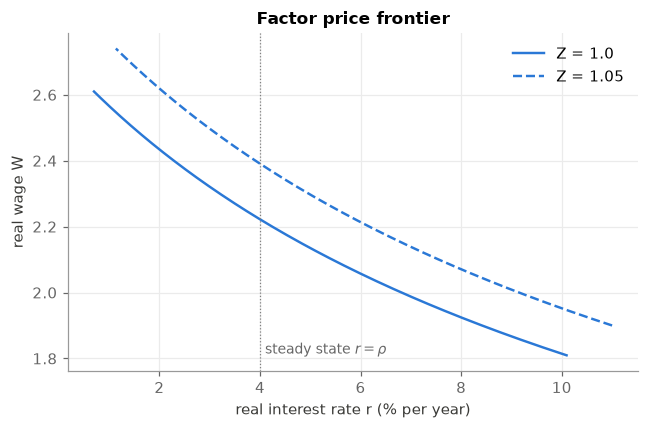

In [2]:
p = rbc.Params()
kl = np.linspace(20, 60, 200)                       # capital-labor ratio
fig, ax = plt.subplots(figsize=(6, 4))
for Z, ls in [(1.0, "-"), (1.05, "--")]:
    W = (1 - p.alpha) * Z * kl ** p.alpha
    r = 400 * (p.alpha * Z * kl ** (p.alpha - 1) - p.delta)     # annualized, %
    ax.plot(r, W, ls=ls, color=COLORS["gdp"], label=f"Z = {Z}")
ax.axvline(400 * p.rho, color="0.5", lw=0.8, ls=":")
ax.text(400 * p.rho + 0.1, ax.get_ylim()[0] + 0.05, r"steady state $r=\rho$", color="0.4", fontsize=9)
ax.set_xlabel("real interest rate r (% per year)"); ax.set_ylabel("real wage W")
ax.set_title("Factor price frontier"); ax.legend()
plt.tight_layout()

## 3. Equilibrium and the steady state

The government buys $G$ (wasteful: it neither provides utility nor raises productivity) and finances it with lump-sum taxes, $G = T$. Wealth is the capital stock, $A = K$. Combining household, firm, and government behavior with goods market clearing $Y = C + I + G$, the equilibrium is described by

$$
\begin{aligned}
\dot K &= Z K^\alpha L^{1-\alpha} - C - G - \delta K, \\
\frac{\dot C}{C} &= \alpha Z K^{\alpha-1}L^{1-\alpha} - \delta - \rho, \\
L^{1/\eta} &= \frac{(1-\alpha) Z K^\alpha L^{-\alpha}}{C}.
\end{aligned}
$$

**Steady state** ($\dot K = \dot C = 0$, $Z = 1$, $G = s_g Y$):

- Euler equation: $r = \rho$, so $\alpha Y/K = \rho + \delta$, which gives $\dfrac{K}{Y} = \dfrac{\alpha}{\rho+\delta}$ and $\dfrac{K}{L} = \left(\dfrac{\alpha}{\rho+\delta}\right)^{\frac{1}{1-\alpha}}$.
- Capital accumulation: $I = \delta K$, so $\dfrac{I}{Y} = \dfrac{\delta\alpha}{\rho+\delta}$ and $\dfrac{C}{Y} = 1 - \dfrac{\delta\alpha}{\rho+\delta} - s_g$.
- Labor supply: $L^{1/\eta} = W/C = (1-\alpha)\dfrac{Y/L}{C}$, so $L^{1+1/\eta} = \dfrac{1-\alpha}{C/Y}$, which gives $\bar L = \left(\dfrac{1-\alpha}{C/Y}\right)^{\frac{\eta}{1+\eta}}$.

All great ratios depend only on parameters. Once $\bar L$ is known, everything else follows.

**Calibration** (time is measured in quarters):

| Parameter | Value | Target |
|---|---|---|
| $\alpha$ | 1/3 | labor share $WL/Y = 2/3$ |
| $\rho$ | 0.01 | $\beta = e^{-\rho} \approx 0.99$, real rate ≈ 4% per year |
| $\delta$ | 0.02 | depreciation ≈ 8% per year (NIPA investment–capital ratio) |
| $\eta$ | 1 | Frisch elasticity |
| $s_g$ | 0.20 | government purchases / GDP |

In [3]:
ss = rbc.steady_state(p)
pd.DataFrame({
    "value": [ss["K"] / ss["Y"] / 4, ss["I"] / ss["Y"], ss["C"] / ss["Y"], ss["G"] / ss["Y"], ss["L"], 400 * ss["r"]],
}, index=["K/Y (annual)", "I/Y", "C/Y", "G/Y", "L", "r (% per year)"])

,value
K/Y (annual),2.778
I/Y,0.222
C/Y,0.578
G/Y,0.200
L,1.074
r (% per year),4.000


The implied capital–output ratio of about 2.8 (annual) and investment share of 22% are in the range of U.S. data.

## 4. Reducing the model to two equations

To draw a phase diagram we need a two-dimensional system. We use the capital stock $K$ (a predetermined **state** variable) and the marginal utility of wealth $\lambda = 1/C$ (a forward-looking **jump** variable). Labor market equilibrium, $L^{1/\eta} = \lambda (1-\alpha) Z K^\alpha L^{-\alpha}$, gives hours as a function of the state:

$$
L = \left[ \lambda (1-\alpha) Z K^\alpha \right]^{\frac{1}{1/\eta + \alpha}} .
$$

Hours rise with $\lambda$ (wealth effect), with $Z$ and with $K$ (both raise labor demand). Substituting into the capital accumulation and Euler equations gives the nonlinear system

$$
\begin{aligned}
\dot K &= Z K^\alpha L(K,\lambda,Z)^{1-\alpha} - \frac{1}{\lambda} - G - \delta K, \\
\dot \lambda &= \lambda\left(\rho + \delta - \alpha Z K^{\alpha - 1} L(K,\lambda,Z)^{1-\alpha}\right).
\end{aligned}
$$

These are `rbc.labor` and `rbc.rhs` in the code.

## 5. Linearization

Let $\hat x = \ln(X/\bar X)$ denote log deviations from the steady state, and let $\hat g = (G - \bar G)/\bar Y$ (spending measured as a share of output). Define $\varphi \equiv \dfrac{1}{1/\eta + \alpha}$.

**Hours and output.** From the labor market and the production function,

$$
\hat l = \varphi\left(\hat\lambda + \hat z + \alpha \hat k\right), \qquad
\hat y = \hat z + \alpha \hat k + (1-\alpha)\hat l .
$$

**Capital.** Linearizing $\dot K = Y - C - G - \delta K$ and dividing by $\bar K$, using $\hat c = -\hat\lambda$:

$$
\dot{\hat k} = \frac{\bar Y}{\bar K}\hat y + \frac{\bar C}{\bar K}\hat\lambda - \frac{\bar Y}{\bar K}\hat g - \delta \hat k .
$$

**Marginal utility.** Linearizing $\dot\lambda/\lambda = \rho + \delta - \alpha Y/K$ and using $\alpha\bar Y/\bar K = \rho+\delta$:

$$
\dot{\hat \lambda} = -(\rho + \delta)(\hat y - \hat k).
$$

Substituting $\hat l$ and $\hat y$, with $m \equiv 1 + (1-\alpha)\varphi$, gives a linear system in $x = (\hat k, \hat\lambda)'$ driven by $s = (\hat z, \hat g)'$:

$$
\begin{pmatrix} \dot{\hat k} \\ \dot{\hat\lambda} \end{pmatrix}
=
\underbrace{\begin{pmatrix}
(\rho+\delta) m - \delta & \frac{\bar Y}{\bar K}(1-\alpha)\varphi + \frac{\bar C}{\bar K} \\[4pt]
(\rho+\delta)(1-\alpha)\varphi/\eta & -(\rho+\delta)(1-\alpha)\varphi
\end{pmatrix}}_{A}
\begin{pmatrix} \hat k \\ \hat\lambda \end{pmatrix}
+
\underbrace{\begin{pmatrix}
\frac{\bar Y}{\bar K} m & -\frac{\bar Y}{\bar K} \\[4pt]
-(\rho+\delta) m & 0
\end{pmatrix}}_{B}
\begin{pmatrix} \hat z \\ \hat g \end{pmatrix}.
$$

(In the top-left entry we used $\frac{\bar Y}{\bar K}\alpha = \rho+\delta$.) Algebra like this is error-prone, so we check it: the code computes $A$ and $B$ from the formulas above and compares them with a finite-difference Jacobian of the *nonlinear* equations.

In [4]:
A, B = rbc.linear_system(p)
A_num, B_num = rbc.numerical_jacobian(p)
print("A =\n", A.round(4))
print("B =\n", B.round(4))
print(f"max |analytic - numerical|: A {np.abs(A - A_num).max():.1e},  B {np.abs(B - B_num).max():.1e}")

A =
 [[ 0.025  0.097]
 [ 0.015 -0.015]]
B =
 [[ 0.135 -0.09 ]
 [-0.045  0.   ]]
max |analytic - numerical|: A 2.8e-12,  B 6.1e-12


## 6. The phase diagram

**The loci.** Setting each equation to zero (with $\hat z = \hat g = 0$):

- $\dot{\hat k} = 0$: $\hat\lambda = -\dfrac{A_{11}}{A_{12}}\hat k$. Since $A_{11} = (\rho+\delta)m - \delta > 0$ and $A_{12} > 0$, this locus is **downward sloping**. Above it, $\lambda$ is high, so consumption is low and labor supply high: capital accumulates ($\dot{\hat k} > 0$).
- $\dot{\hat\lambda} = 0$: $\hat\lambda = \hat k / \eta$. This locus is **upward sloping**. To its right, capital is abundant and the marginal product of capital is low: $r < \rho$, so consumption falls and $\lambda$ rises.

**Saddle-path stability.** $\det A = A_{11}A_{22} - A_{12}A_{21} < 0$, so $A$ has one negative eigenvalue $\mu_s$ and one positive eigenvalue $\mu_u$. Capital is predetermined, but $\lambda$ can jump. For any initial capital stock there is exactly one value of $\lambda$ that puts the economy on the **stable arm** (the eigenvector of $\mu_s$), along which it converges to the steady state. Every other choice leads to explosive paths that violate the transversality condition or eventually require negative capital. On the stable arm

$$
\hat\lambda(t) = \nu\, \hat k(t), \qquad \hat k(t) = e^{\mu_s t}\hat k(0),
$$

so the economy closes the gap to the steady state at rate $|\mu_s|$. This is the continuous-time counterpart of the discrete-time coefficient $\nu_{kk}$ in the policy rule $\hat k_{t} = \nu_{kk}\hat k_{t-1}$, with $\nu_{kk} \approx e^{\mu_s}$.

In [5]:
mu_s, mu_u, P = rbc.saddle(A)
nu = rbc.stable_arm_slope(p)
print(f"eigenvalues: mu_s = {mu_s:.4f}, mu_u = {mu_u:.4f}   (det A = {np.linalg.det(A):.5f} < 0)")
print(f"stable arm: lambda_hat = {nu:.3f} * k_hat;  half-life of capital gap = {np.log(2)/-mu_s:.1f} quarters;  "
      f"discrete-time equivalent nu_kk = e^mu_s = {np.exp(mu_s):.3f}")

eigenvalues: mu_s = -0.0381, mu_u = 0.0481   (det A = -0.00183 < 0)
stable arm: lambda_hat = -0.650 * k_hat;  half-life of capital gap = 18.2 quarters;  discrete-time equivalent nu_kk = e^mu_s = 0.963


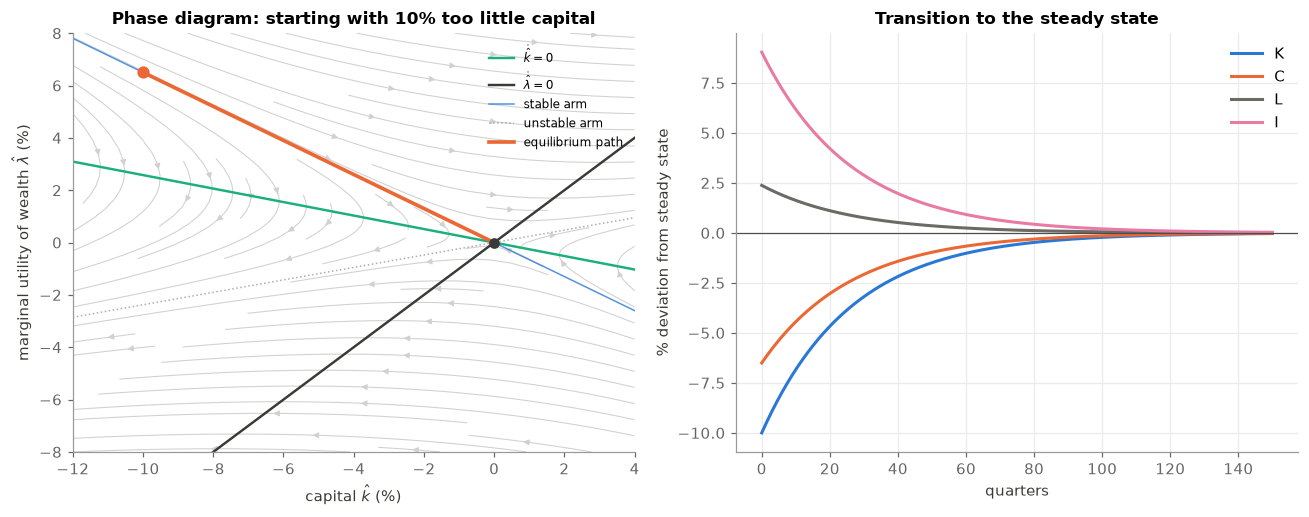

In [6]:
def phase_diagram(ax, p, z=0.0, g=0.0, z_new=None, g_new=None, path=None, lim=(-3, 3, -3, 3), arms=True):
    # Phase diagram in (k_hat, lambda_hat), in %. Grey loci: dynamics with shocks (z, g);
    # coloured dashed loci: shifted dynamics (z_new, g_new). path: DataFrame from rbc.irf.
    kmin, kmax, lmin, lmax = lim
    A, B = rbc.linear_system(p)
    zf, gf = (z, g) if z_new is None else (z_new, g_new)
    # vector field of the dynamics that apply on impact
    kk, ll = np.meshgrid(np.linspace(kmin, kmax, 25), np.linspace(lmin, lmax, 25))
    s = B @ np.array([zf, gf]) * 100
    U = A[0, 0] * kk + A[0, 1] * ll + s[0]
    V = A[1, 0] * kk + A[1, 1] * ll + s[1]
    ax.streamplot(kk, ll, U, V, color="0.82", density=0.9, linewidth=0.7, arrowsize=0.8)
    kgrid = np.linspace(kmin, kmax, 50)
    k0, l0 = rbc.loci(p, kgrid / 100, z, g)
    ax.plot(kgrid, 100 * k0, color="#1baf7a", lw=1.6, label=r"$\dot{\hat k}=0$")
    ax.plot(kgrid, 100 * l0, color=COLORS["text"], lw=1.6, label=r"$\dot{\hat\lambda}=0$")
    if z_new is not None:
        k1, l1 = rbc.loci(p, kgrid / 100, z_new, g_new)
        ax.plot(kgrid, 100 * k1, color="#1baf7a", lw=1.6, ls="--", label=r"$\dot{\hat k}=0$ (shifted)")
        ax.plot(kgrid, 100 * l1, color=COLORS["text"], lw=1.6, ls="--", label=r"$\dot{\hat\lambda}=0$ (shifted)")
    if arms:
        mu_s, mu_u, P = rbc.saddle(A)
        for j, (lab, ls) in enumerate([("stable arm", "-"), ("unstable arm", ":")]):
            slope = P[1, j] / P[0, j]
            ax.plot(kgrid, slope * kgrid, color=COLORS["gdp"] if j == 0 else "0.6", lw=1.0, ls=ls, alpha=0.8, label=lab)
    if path is not None:
        ax.plot(path["K"], path["lambda"], color=COLORS["series"], lw=2.4, label="equilibrium path")
        ax.plot(path["K"].iloc[0], path["lambda"].iloc[0], "o", color=COLORS["series"], ms=7)
        ax.plot([0, path["K"].iloc[0]], [0, path["lambda"].iloc[0]], color=COLORS["series"], lw=1.2, ls=":")
        ax.plot(0, 0, "o", color=COLORS["text"], ms=6)
    ax.set_xlim(kmin, kmax); ax.set_ylim(lmin, lmax)
    ax.set_xlabel(r"capital $\hat k$ (%)"); ax.set_ylabel(r"marginal utility of wealth $\hat\lambda$ (%)")
    ax.grid(False)
    return ax


# Convergence from a capital stock 10% below steady state
path = rbc.irf(p, k0=-0.10, T=150)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
phase_diagram(axes[0], p, path=path, lim=(-12, 4, -8, 8))
axes[0].set_title("Phase diagram: starting with 10% too little capital")
axes[0].legend(loc="upper right", fontsize=8)
for v, col in [("K", COLORS["gdp"]), ("C", COLORS["series"]), ("L", COLORS["trend"]), ("I", "#e87ba4")]:
    axes[1].plot(path.index, path[v], color=col, lw=2, label=v)
axes[1].axhline(0, color="0.3", lw=0.8)
axes[1].set_xlabel("quarters"); axes[1].set_ylabel("% deviation from steady state")
axes[1].set_title("Transition to the steady state"); axes[1].legend()
plt.tight_layout()

With too little capital, the marginal product of capital and the interest rate are high. The household starts on the stable arm with high $\lambda$: it consumes little and works hard, and investment is far above its steady-state level. As capital accumulates, the interest rate falls, consumption rises, hours fall back, and investment declines monotonically toward its steady-state level.

## 7. Responses to shocks

We study **unanticipated** shocks at $t = 0$ that follow a known path afterwards (so-called "MIT shocks"):

$$
\hat z(t) = \hat z_0\, e^{-\theta_z t}, \qquad \hat g(t) = \hat g_0\, e^{-\theta_g t}.
$$

$\theta = 0$ is a permanent shock; $\theta > 0$ a transitory one with half-life $\ln 2/\theta$. We use $\theta = -\ln 0.95 \approx 0.05$ (quarterly persistence 0.95, the standard RBC calibration).

**Solution.** Write $A = P\,\mathrm{diag}(\mu_s, \mu_u)\,P^{-1}$ and $w = P^{-1}x$. Each component obeys a scalar equation $\dot w_j = \mu_j w_j + b_j e^{-\theta t}$ with $b = P^{-1}B s_0$.
- The **unstable** component must stay bounded, so it is solved *forward*: $w_u(t) = -\dfrac{b_u}{\mu_u + \theta} e^{-\theta t}$.
- The **stable** component is solved *backward* from the predetermined capital stock, $\hat k(0) = 0$: $w_s(t) = -\dfrac{b_s}{\mu_s+\theta}e^{-\theta t} + c\,e^{\mu_s t}$, with $c$ chosen so that $\hat k(0)=0$.

So $\hat\lambda$ jumps at $t=0$ while $\hat k$ does not. This is `rbc.irf`. From $(\hat k, \hat\lambda, \hat z, \hat g)$ we recover all other variables: $\hat l$, $\hat y$, $\hat c = -\hat\lambda$, $\hat\imath = (\dot{\hat k} + \delta\hat k)/\delta$, $\hat w = \hat y - \hat l$, and $dr = (\rho+\delta)(\hat y - \hat k)$, which we report annualized in percentage points.

In [7]:
theta = -np.log(0.95)          # quarterly persistence 0.95
irf_vars = ["K", "C", "L", "Y", "I", "W", "r (ann. p.p.)"]


def show_experiment(title, z0=0.0, g0=0.0, theta_z=0.0, theta_g=0.0, lim=(-1.5, 1.5, -2, 2), T=100):
    path = rbc.irf(p, z0=z0, g0=g0, theta_z=theta_z, theta_g=theta_g, T=T, n=4 * T + 1)
    fig = plt.figure(figsize=(14, 5))
    gs = fig.add_gridspec(2, 5, width_ratios=[2.2, 1, 1, 1, 1])
    ax = fig.add_subplot(gs[:, 0])
    phase_diagram(ax, p, z=0, g=0, z_new=z0, g_new=g0, path=path, lim=lim)
    ax.legend(loc="best", fontsize=7)
    ax.set_title(title)
    shock = "Z" if z0 else "G/Y"
    for n, v in enumerate([shock] + irf_vars):
        a = fig.add_subplot(gs[n // 4, 1 + n % 4])
        a.plot(path.index, path[v], color=COLORS["series"] if v == shock else COLORS["gdp"], lw=2)
        a.axhline(0, color="0.3", lw=0.7)
        a.set_title(v + (" (shock)" if v == shock else ""), fontsize=9)
        if n >= 4: a.set_xlabel("quarters", fontsize=8)
    plt.tight_layout()
    return path

### 7.1 A permanent increase in government spending

$\hat g_0 = 0.01$ (spending rises by 1% of GDP forever). Higher $G$ shifts the $\dot{\hat k}=0$ locus **up**: to keep capital constant, the household must consume less. The $\dot{\hat\lambda}=0$ locus does not move, because $G$ does not enter the Euler equation.

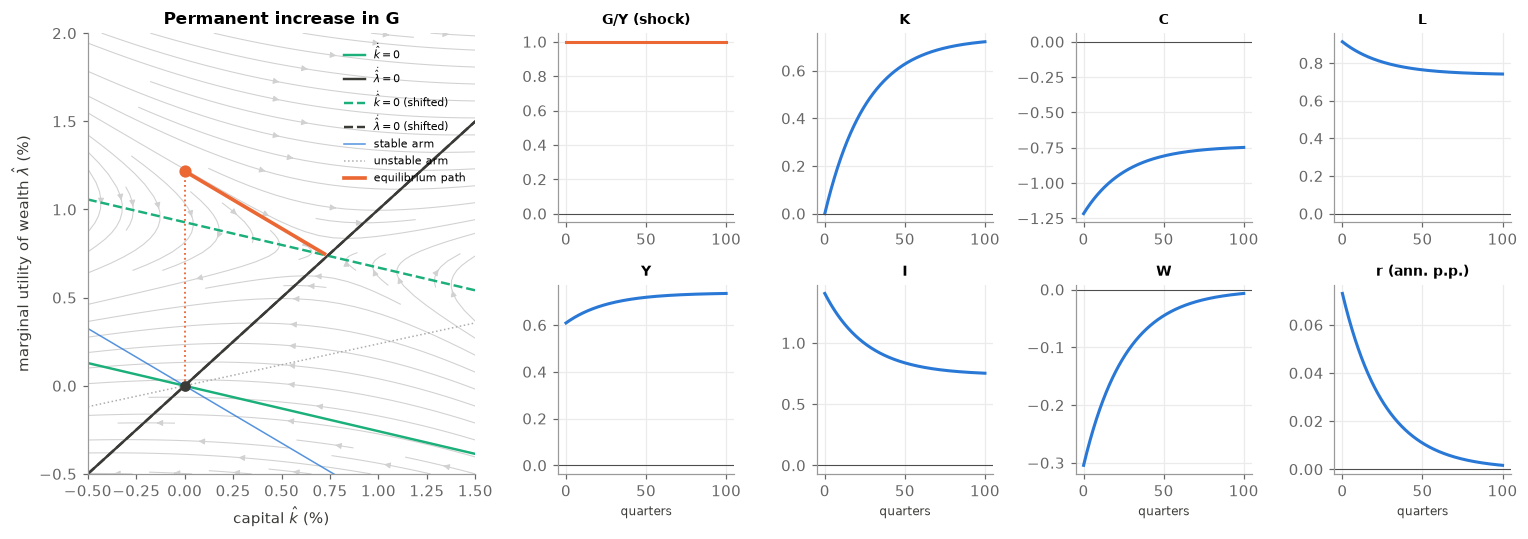

In [8]:
out = show_experiment("Permanent increase in G", g0=0.01, lim=(-0.5, 1.5, -0.5, 2))

Higher taxes make the household poorer, so $\lambda$ jumps up: consumption falls and, through the wealth effect on labor supply, hours rise. More hours raise the marginal product of capital, so the interest rate rises and the economy accumulates capital toward a new steady state with higher $K$, $L$, and $Y$ and lower $C$. The wage falls on impact (more hours with the same capital) and returns to its old level, because in the long run $K/L$ is pinned down by $r = \rho$. In the new steady state output rises by less than spending: the **multiplier** $dY/dG$ is below one.

### 7.2 A transitory increase in government spending

Now spending decays with persistence 0.95. The $\dot{\hat k}=0$ locus shifts up on impact and then gradually moves back.

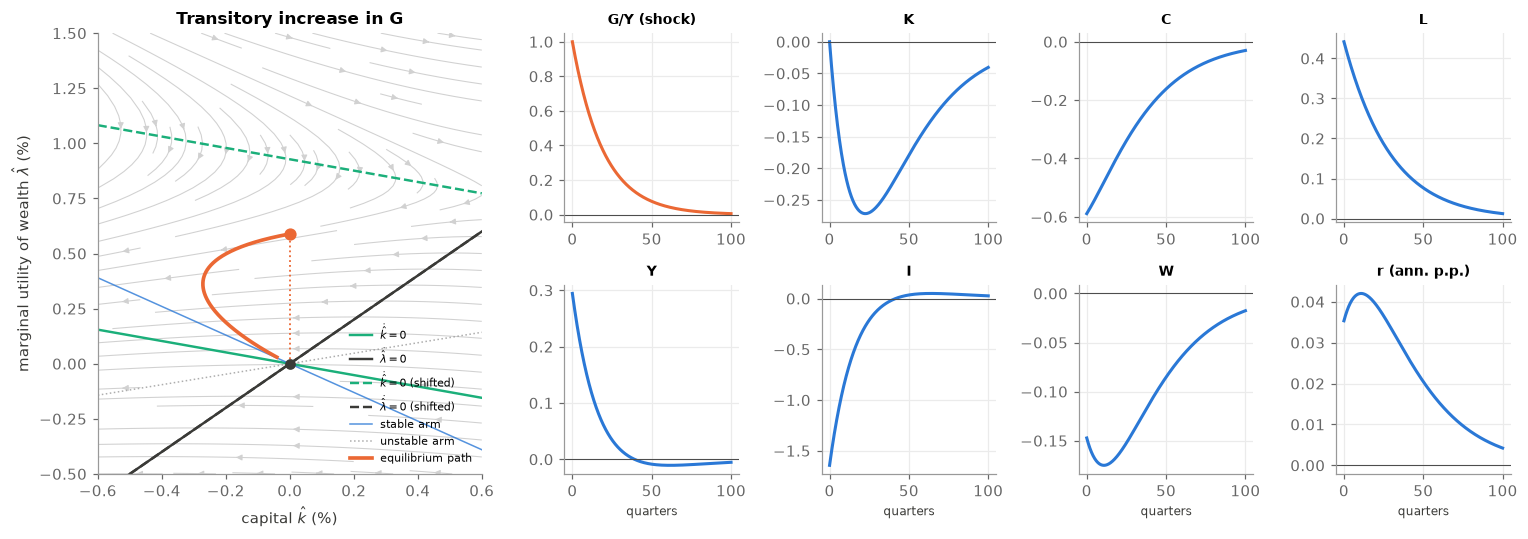

In [9]:
out = show_experiment("Transitory increase in G", g0=0.01, theta_g=theta, lim=(-0.6, 0.6, -0.5, 1.5))

Because the tax burden is temporary, the household is poorer by much less: $\lambda$ jumps by only about half as much as in the permanent case, and hours rise by less. With a smaller labor-supply response, extra spending now **crowds out investment**: capital falls while spending is high and recovers afterward. The economy does not jump to the stable arm of the original system. It moves along a path that returns to the original steady state as the shock dies out.

### 7.3 A permanent increase in productivity

$\hat z_0 = 0.01$ forever. Both loci shift: the $\dot{\hat\lambda}=0$ locus moves **down/right** (a higher MPK requires more capital to bring $r$ back to $\rho$), and the $\dot{\hat k}=0$ locus moves down (more output is available for consumption).

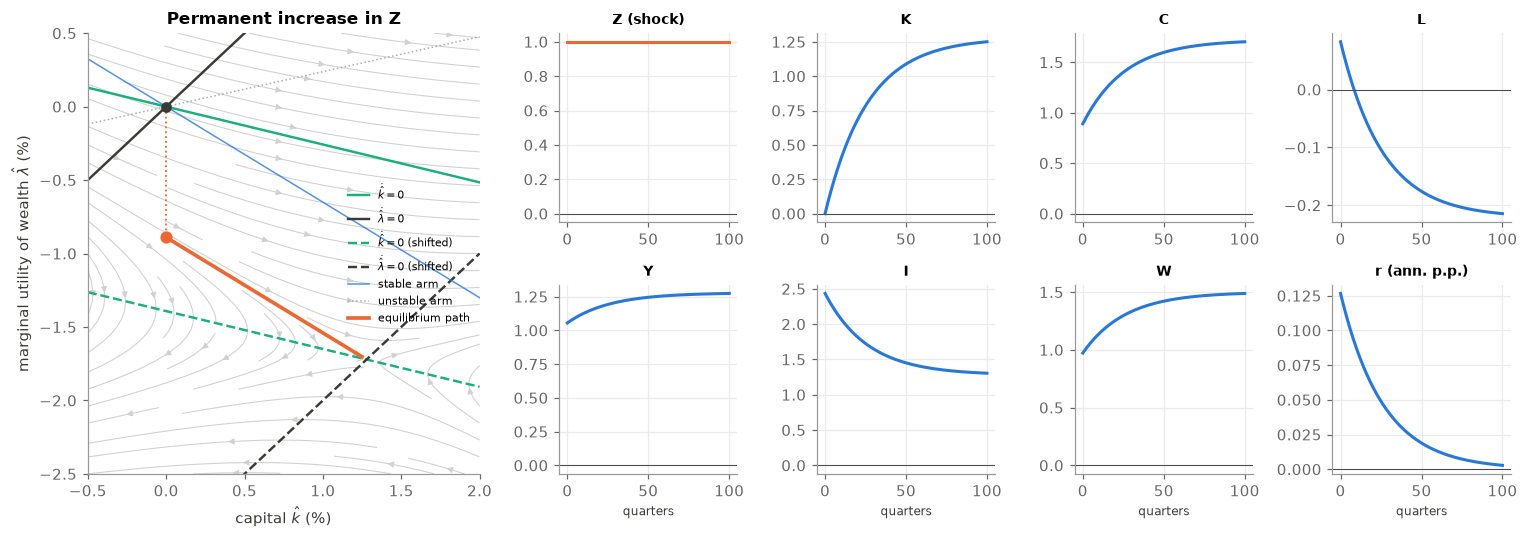

In [10]:
out = show_experiment("Permanent increase in Z", z0=0.01, lim=(-0.5, 2, -2.5, 0.5))

The household is richer, so $\lambda$ falls (consumption jumps up), and the higher return to capital raises investment. Hours barely move on impact: the substitution effect of the higher wage roughly cancels the wealth effect. In the long run the real rate returns to $\rho$, so $K/L$ and the wage rise by $1/(1-\alpha) \approx 1.5\%$: wages absorb the productivity gain. Capital and output rise by somewhat less (about 1.3%) because hours end slightly *lower*: $G$ is held fixed in levels, so the tax burden falls relative to income and the wealth effect reduces labor supply. With $G/Y$ held constant instead, hours would return exactly to their old level, as the steady-state formula for $\bar L$ shows.

### 7.4 A transitory increase in productivity

This is the central experiment of RBC theory: $\hat z_0 = 0.01$ with persistence 0.95.

,K,lambda,C,L,Y,I,W,Z,G/Y,r (ann. p.p.)
t,,,,,,,,,,
0.0,0.00,-0.43,0.43,0.43,1.28,4.66,0.86,1.00,0.0,0.15
4.0,0.31,-0.55,0.55,0.27,1.10,3.52,0.83,0.81,0.0,0.09
20.0,0.77,-0.65,0.65,-0.03,0.59,0.98,0.62,0.36,0.0,-0.02


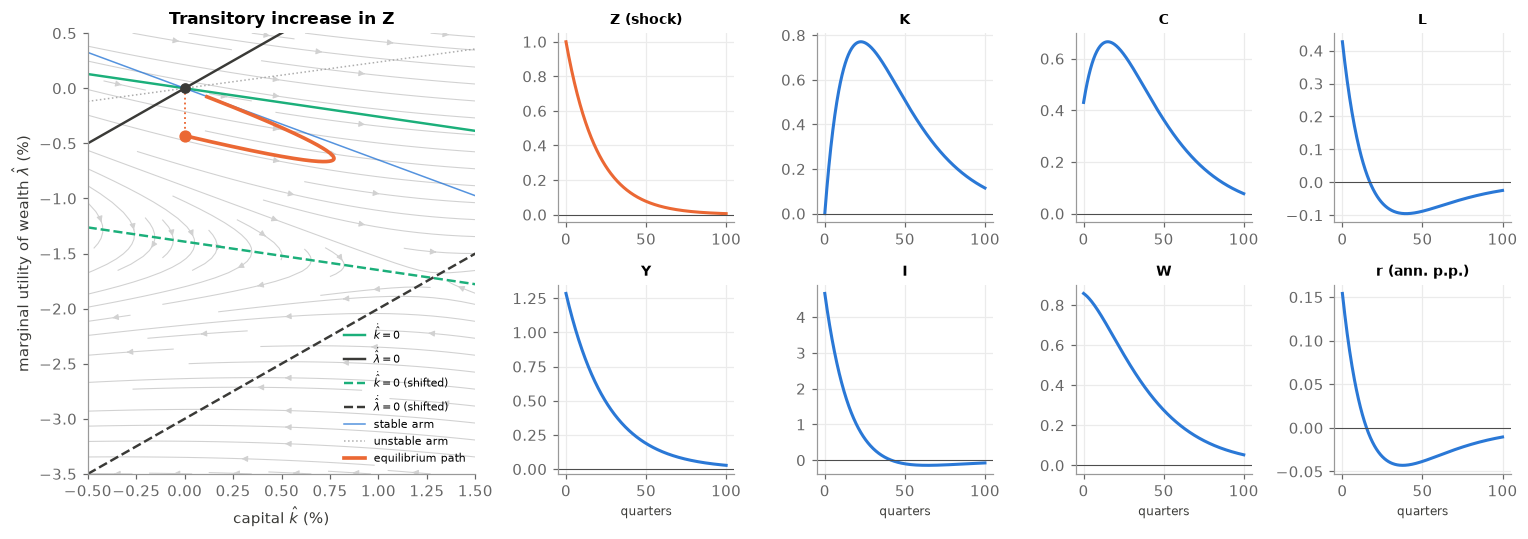

In [11]:
out = show_experiment("Transitory increase in Z", z0=0.01, theta_z=theta, lim=(-0.5, 1.5, -3.5, 0.5))
out.loc[[0, 4, 20]].round(2)

Because the productivity gain is temporary, wealth rises only modestly: $\lambda$ falls by less than in the permanent case. The wage is temporarily high, so the household **substitutes intertemporally**: it works more now, while work pays well, and saves most of the extra income by investing. Output, consumption, investment, and hours all rise together, investment by far the most, as in the data. As the shock fades, hours and investment fall back while the accumulated capital keeps output and consumption elevated for a while.

**Compare with Lecture 1, Section 5.** The model reproduces the comovement of output, consumption, investment, and hours after a TFP shock. But on impact the real wage rises by about *twice* as much as hours ($\hat w = \hat y - \hat l$), while in the data hours respond strongly and the real wage barely moves. This is the point made by [Barro and King (1984)](https://doi.org/10.2307/1883127): with time-separable preferences, $L^{1/\eta} = W/C$ must hold at every date, so when consumption and hours rise together the real wage must rise strongly. Matching the weak cyclicality of wages requires either a very elastic labor supply or something that moves the labor-supply curve, which will be a recurring theme.

## 8. Checking the linear solution against the nonlinear model

The linearization is only a local approximation. We can compute the exact perfect-foresight transition of the *nonlinear* model by solving a two-point boundary value problem: $K(0)$ is given by the old steady state, and $\lambda(T)$ must equal its new steady-state value for some large $T$ (`rbc.nonlinear_path`, using `scipy.integrate.solve_bvp`). The figure compares the two for a transitory productivity shock of 1% and of 10%.

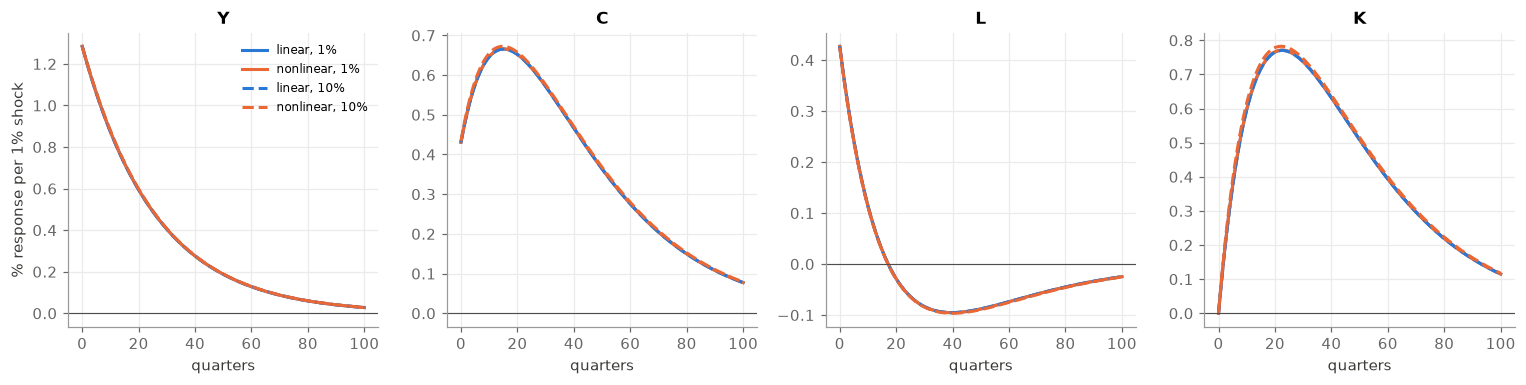

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for size, ls in [(0.01, "-"), (0.10, "--")]:
    lin = rbc.irf(p, z0=size, theta_z=theta, T=100, n=401)
    nl, ss0 = rbc.nonlinear_path(p, Zpath=lambda t: np.exp(size * np.exp(-theta * t)),
                                 Gpath=lambda t: ss["G"] + 0 * t, T=300, n=1201)
    nl = nl.loc[:100]
    for ax, v in zip(axes, ["Y", "C", "L", "K"]):
        ax.plot(lin.index, lin[v] / (100 * size), color=COLORS["gdp"], lw=2, ls=ls, label=f"linear, {size:.0%}")
        ax.plot(nl.index, np.log(nl[v] / ss0[v]) / size, color=COLORS["series"], lw=2, ls=ls,
                label=f"nonlinear, {size:.0%}")
        ax.set_title(v); ax.axhline(0, color="0.3", lw=0.7); ax.set_xlabel("quarters")
axes[0].set_ylabel("% response per 1% shock")
axes[0].legend(fontsize=8)
plt.tight_layout()

Responses are scaled by the size of the shock. For a 1% shock the linear and nonlinear paths are indistinguishable. For a 10% shock, which is very large by business cycle standards, the differences are still small. The linearized model is an excellent guide to the dynamics of the RBC model at business cycle frequencies.

## 9. Try it yourself

1. **Frisch elasticity.** Rerun the transitory TFP experiment with `p = rbc.Params(eta=4)` and `eta=0.25`. How do the responses of hours and wages change? Can a high Frisch elasticity resolve the wage–hours puzzle? What does the micro evidence say about $\eta$?
2. **Persistence.** Vary `theta` for the TFP shock between 0 (permanent) and 0.5. Plot the impact response of hours against the half-life of the shock. Explain the pattern using the forward-looking nature of $\lambda$.
3. **Speed of convergence.** How does the half-life of the capital gap depend on $\delta$, $\alpha$, and $\eta$? Use `rbc.saddle(rbc.linear_system(p)[0])`.
4. **Multipliers.** Compute the impact and long-run output multiplier $dY/dG$ for permanent and transitory spending shocks. Why is the long-run multiplier for a permanent increase larger than the impact multiplier?
5. **Phase diagram in $(K, C)$.** Redraw the phase diagram with consumption instead of $\lambda$ on the vertical axis ($\hat c = -\hat\lambda$). Which loci change slope?
6. **Anticipated shocks.** Suppose at $t=0$ it becomes known that $Z$ will rise permanently by 1% at $t = 8$. Sketch the path in the phase diagram. (Hint: between $t=0$ and $t=8$ the economy follows the *old* dynamics and must arrive exactly on the *new* stable arm at $t=8$.)

## Summary

- The household's optimality conditions are an intratemporal condition $L^{1/\eta} = W/C$ and an Euler equation $\dot C/C = r - \rho$. The firm's are $W = MPL$ and $r + \delta = MPK$.
- In $(K, \lambda)$ space the model is a saddle: capital is predetermined, $\lambda$ jumps onto the stable arm, and the economy converges at rate $|\mu_s|$.
- Permanent shocks move the steady state and shift $\lambda$ strongly. Transitory shocks move $\lambda$ little, and their effects on hours work mainly through intertemporal substitution.
- A transitory productivity shock generates the comovement of output, consumption, investment, and hours seen in the data, but with a real wage that is too procyclical.

**Next lecture.** We ask how well the model does quantitatively: we simulate it with stochastic shocks and compare its second moments with the business cycle facts from Lecture 1.